# SentiScope - Sentiment Analysis Model Training

## Objective

This notebook develops the Machine Learning model used in the SentiScope Customer Feedback Analysis Platform.

The workflow includes:

- Loading the IMDb Reviews dataset
- Exploring and understanding the data
- Cleaning and preprocessing review text
- Converting text into numerical features using TF-IDF
- Training a Logistic Regression classifier
- Evaluating model performance
- Saving the trained model and TF-IDF vectorizer for integration with the Flask application

The trained model will later be used by the SentiScope web application to predict customer sentiment and confidence scores.

In [2]:
# ============================================================
# Import Required Libraries
# ============================================================

# Data Handling
import pandas as pd
import numpy as np

# Text Processing
import re
import string

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Model Saving
import joblib

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# ============================================================
# Project Configuration
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20

DATASET_PATH = "datasets/imdb_reviews.csv"

MODEL_PATH = "models/sentiment_model.pkl"
VECTORIZER_PATH = "models/tfidf_vectorizer.pkl"

In [4]:
import nltk

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\aquil\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\aquil\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\aquil\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [5]:
df = pd.read_csv(DATASET_PATH)

df.head()

,review,sentiment
0,"$25,000 Pyramid Clues: Deep Blue Sea. Tremors....",negative
1,0.5/10. This movie has absolutely nothing good...,negative
2,"0*'s Christian Slater, Tara Reid, Stephen Dorf...",negative
3,"102 Dalmatians (2000, Dir. Kevin Lima) <br /><...",negative
4,102 DALMATIANS [Walt Disney]: I wasn't a fan o...,negative


In [6]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

Shape: (49396, 2)

Columns:
Index(['review', 'sentiment'], dtype='object')

Missing Values:
review       0
sentiment    0
dtype: int64

Data Types:
review       object
sentiment    object
dtype: object

Sentiment Distribution:
sentiment
negative    24698
positive    24698
Name: count, dtype: int64


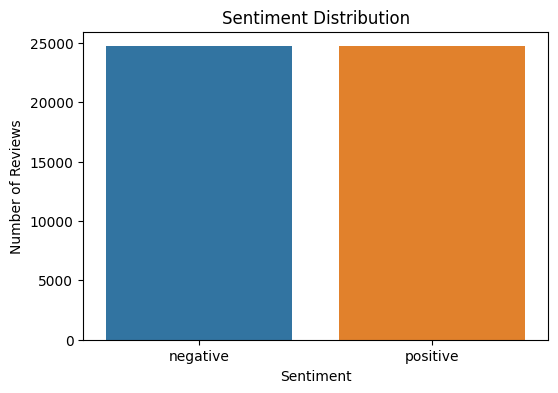

In [7]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    legend=False
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [8]:
df["review_length"] = df["review"].apply(len)

df["review_length"].describe()

count    49396.000000
mean      1310.542331
std        990.722799
min         32.000000
25%        699.000000
50%        971.000000
75%       1591.250000
max      13704.000000
Name: review_length, dtype: float64

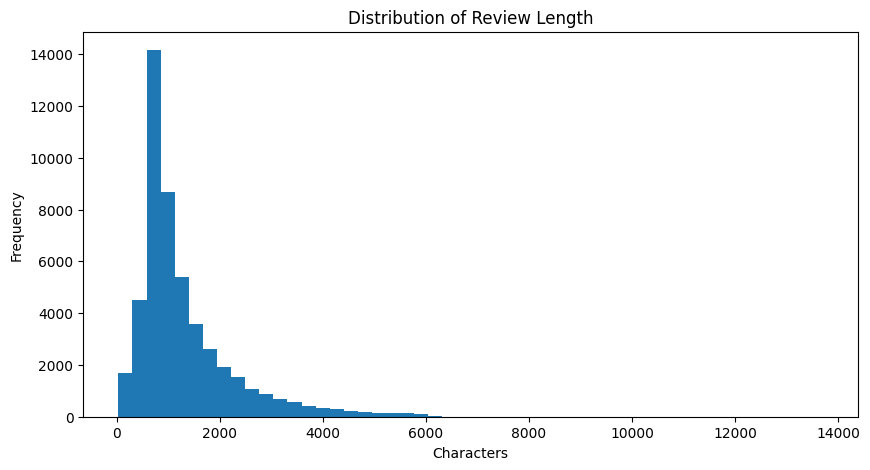

In [9]:
plt.figure(figsize=(10,5))

plt.hist(
    df["review_length"],
    bins=50
)

plt.title("Distribution of Review Length")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

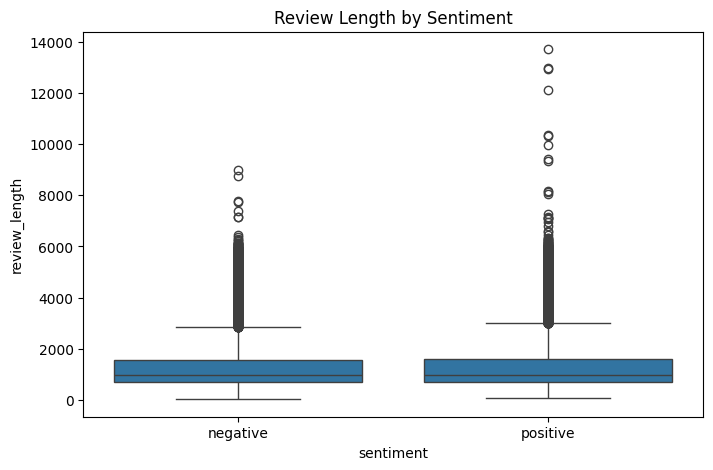

In [10]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="review_length"
)

plt.title("Review Length by Sentiment")

plt.show()

## Text Preprocessing

Before training the machine learning model, the review text must be cleaned and standardized.

The preprocessing steps performed are:

- Remove HTML tags
- Convert text to lowercase
- Remove punctuation
- Remove numbers
- Remove extra spaces
- Remove stopwords
- Apply lemmatization

These steps help improve the quality of the text representation and reduce noise in the dataset.

In [11]:
# Initialize NLP Tools

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [12]:
def clean_text(text):
    """
    Cleans a review by:
    - Removing HTML tags
    - Converting to lowercase
    - Removing punctuation
    - Removing numbers
    - Removing extra spaces
    - Removing stopwords
    - Applying lemmatization
    """

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Remove numbers
    text = re.sub(r"\d+", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenize
    words = text.split()

    # Remove stopwords and lemmatize
    cleaned_words = []

    for word in words:
        if word not in stop_words:
            cleaned_words.append(
                lemmatizer.lemmatize(word)
            )

    return " ".join(cleaned_words)

In [13]:
print("Cleaning reviews...")

df["clean_review"] = df["review"].apply(clean_text)

print("Cleaning completed!")

Cleaning reviews...
Cleaning completed!


In [14]:
print("=" * 80)
print("ORIGINAL REVIEW")
print("=" * 80)

print(df.loc[0, "review"])

print("\n")

print("=" * 80)
print("CLEANED REVIEW")
print("=" * 80)

print(df.loc[0, "clean_review"])

ORIGINAL REVIEW
$25,000 Pyramid Clues: Deep Blue Sea. Tremors. Slither. Eight Legged Freaks.<br /><br />Pyramid Category: Movies that were funnier and more thrilling than Snakes on a Plane.<br /><br />Hell, with that definition I'd have to include the relatively harrowing journey of Ted and Elaine in Airplane! as superior to Snakes in both laughs and thrills.<br /><br />The sad truth is that this isn't even close to the mother of all unintentionally intentional funny snake movies: Anaconda! Besides the never to be seen again casting of JLo-Cube-O.Wilson-Stoltz-Wuhrer in the same flick, you had Jon Voight pulling off the all-time cinematic heist. His final scene alone represents everything SOAP tried and failed to do as a "so-ludicrous-it's-fun" movie.<br /><br />In the end, Snakes on a Plane is definitive proof that studio execs and fanboys make the worst collaborators possible. Every big scene had been discussed and dissected so much the last year, all that was left to amuse by openin

## Train-Test Split

The cleaned dataset is divided into training and testing sets.

- Training Data: 80%
- Testing Data: 20%

The random state is fixed to ensure reproducibility of the results.

In [15]:
# ============================================================
# Train-Test Split
# ============================================================

X = df["clean_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training Samples :", len(X_train))
print("Testing Samples  :", len(X_test))

Training Samples : 39516
Testing Samples  : 9880


## TF-IDF Feature Extraction

Machine learning algorithms cannot process raw text directly.

TF-IDF (Term Frequency–Inverse Document Frequency) converts text into numerical feature vectors while assigning higher importance to informative words and reducing the influence of very common words.

In [16]:
# ============================================================
# TF-IDF Vectorization
# ============================================================

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training Matrix Shape :", X_train_tfidf.shape)
print("Testing Matrix Shape  :", X_test_tfidf.shape)

Training Matrix Shape : (39516, 5000)
Testing Matrix Shape  : (9880, 5000)


## Logistic Regression Model Training

A Logistic Regression classifier is trained using the TF-IDF feature vectors.

This algorithm is selected because it performs well for text classification, is computationally efficient, and provides probability estimates that can later be used as confidence scores in the SentiScope application.

In [17]:
# ============================================================
# Logistic Regression Training
# ============================================================

model = LogisticRegression(
    random_state=RANDOM_STATE,
    max_iter=1000
)

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


## Model Evaluation

The trained Logistic Regression model is evaluated using the testing dataset.

The following evaluation metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-Score
- Classification Report
- Confusion Matrix

These metrics help assess the effectiveness of the sentiment classifier.

In [20]:
# ============================================================
# Model Evaluation
# ============================================================

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="positive")
recall = recall_score(y_test, y_pred, pos_label="positive")
f1 = f1_score(y_test, y_pred, pos_label="positive")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Accuracy : 0.8886
Precision: 0.8785
Recall   : 0.9018
F1 Score : 0.8900


In [21]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    negative       0.90      0.88      0.89      4940
    positive       0.88      0.90      0.89      4940

    accuracy                           0.89      9880
   macro avg       0.89      0.89      0.89      9880
weighted avg       0.89      0.89      0.89      9880



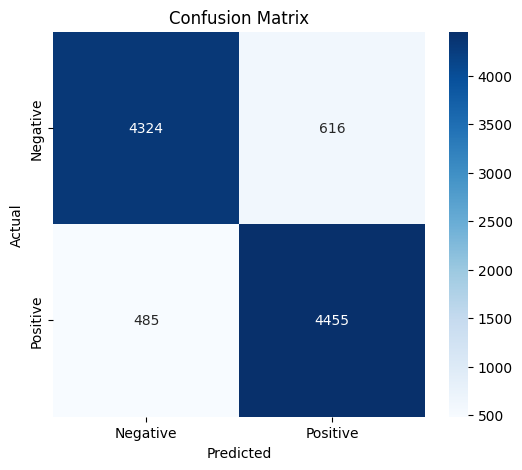

In [22]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [23]:
# ============================================================
# Top Positive and Negative Words
# ============================================================

feature_names = vectorizer.get_feature_names_out()

coefficients = model.coef_[0]

coef_df = pd.DataFrame({
    "Word": feature_names,
    "Coefficient": coefficients
})

positive_words = coef_df.sort_values(
    by="Coefficient",
    ascending=False
).head(20)

negative_words = coef_df.sort_values(
    by="Coefficient"
).head(20)

print("Top Positive Words")
display(positive_words)

print("\nTop Negative Words")
display(negative_words)

Top Positive Words


,Word,Coefficient
1411,excellent,6.856857
1904,great,6.699050
3262,perfect,5.438092
143,amazing,4.958230
4895,wonderful,4.932154
2045,hilarious,4.609680
1516,favorite,4.484296
3118,one best,4.401146
4506,today,4.267595
364,best,4.234388



Top Negative Words


,Word,Coefficient
4915,worst,-9.185541
274,awful,-7.568539
284,bad,-7.082138
4788,waste,-6.529123
441,boring,-6.270487
3364,poor,-5.926216
4393,terrible,-5.745353
2090,horrible,-5.406153
3059,nothing,-5.236972
1230,dull,-5.051978


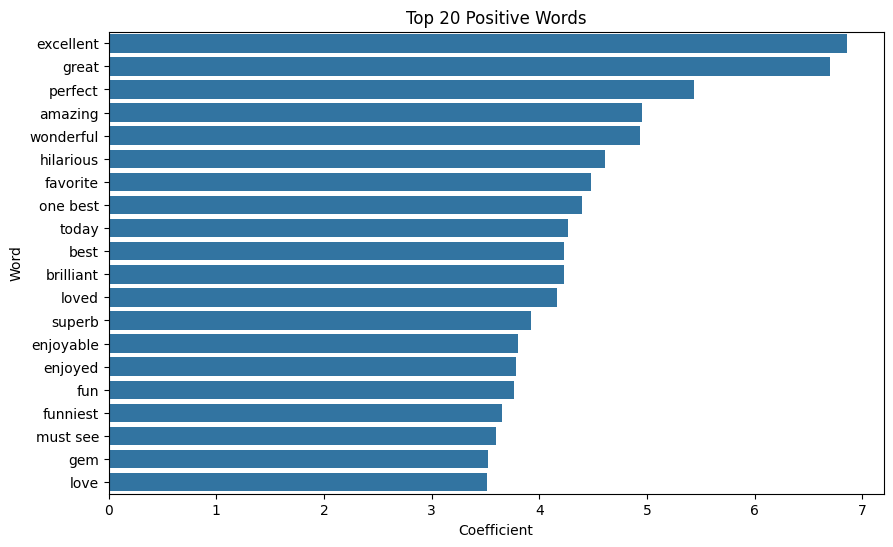

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=positive_words,
    x="Coefficient",
    y="Word"
)

plt.title("Top 20 Positive Words")

plt.show()

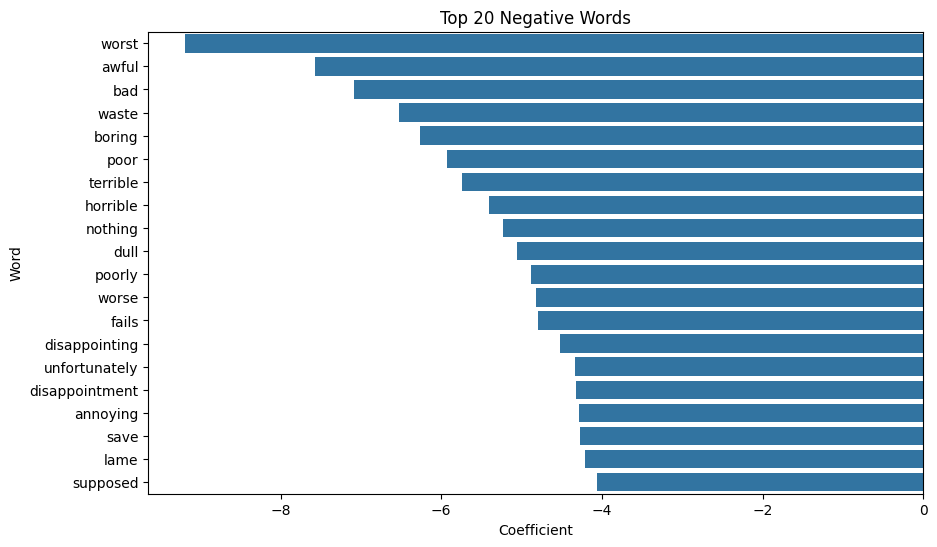

In [25]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=negative_words,
    x="Coefficient",
    y="Word"
)

plt.title("Top 20 Negative Words")

plt.show()

In [26]:
joblib.dump(model, MODEL_PATH)
joblib.dump(vectorizer, VECTORIZER_PATH)

print("Model Saved Successfully!")

Model Saved Successfully!


In [28]:
sample_reviews = [
    "This movie was amazing!",
    "Worst movie I have ever watched.",
    "The acting was decent but the story was boring.",
    "Absolutely fantastic experience."
]

sample_vectors = vectorizer.transform(sample_reviews)

predictions = model.predict(sample_vectors)
probabilities = model.predict_proba(sample_vectors)

for review, prediction, probability in zip(
    sample_reviews,
    predictions,
    probabilities
):

    confidence = max(probability) * 100

    print("=" * 80)
    print(f"Review      : {review}")
    print(f"Sentiment   : {prediction.capitalize()}")
    print(f"Confidence  : {confidence:.2f}%")

Review      : This movie was amazing!
Sentiment   : Positive
Confidence  : 98.80%
Review      : Worst movie I have ever watched.
Sentiment   : Negative
Confidence  : 99.78%
Review      : The acting was decent but the story was boring.
Sentiment   : Negative
Confidence  : 99.29%
Review      : Absolutely fantastic experience.
Sentiment   : Positive
Confidence  : 93.97%
